# Лекция 2: порог решения, цена ошибки и чувствительные точки

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Материалы лекции 2 (`docs/14_10_26_PREL_2_DEC_BOUND`) переносят акцент с метрик на **решения**:
- граница решений — это механизм, превращающий вероятности модели в действия; её положение задаёт **порог**;
- выбор порога — **экономическое решение**: важны не accuracy или F1, а **стоимость ошибок** (False Positive, False Negative) и **выгода от верных решений** (True Positive, True Negative);
- «**максимальный F1 ≠ минимальная стоимость**»;
- **чувствительные точки** — наблюдения у самой границы: именно их шум и смещение перебрасывают в другой класс.

Ниже всё это применено к нашей задаче: модель Random Forest из ноутбука 02 прогнозирует осадки на завтра, а решение принимает конкретный пользователь прогноза.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_dataset
from features import FEATURES, TARGET
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, accuracy_score

FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET = "#E0A030", "#2B6CB0"
SEED = 42

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

data = load_dataset("chisinau")
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024]
bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rf, THR_F1 = bundle["model"], bundle["threshold"]
y_va, y_te = valid[TARGET].to_numpy(), test[TARGET].to_numpy()
p_va, p_te = rf.predict_proba(valid[FEATURES])[:, 1], rf.predict_proba(test[FEATURES])[:, 1]
print(f"Модель: {bundle['model_name']}; порог, выбранный по F1 на валидации: {THR_F1:.2f}")

def cells4(y, p, t):
    tn, fp, fn, tp = confusion_matrix(y, (p >= t).astype(int), labels=[0, 1]).ravel()
    return tp, fp, fn, tn

Модель: Random Forest; порог, выбранный по F1 на валидации: 0.23


---
## 1. Порог как граница решений: 0.3, 0.5, 0.8 и наш 0.23

Как в материалах (части 1–2 лекции), сравниваем пороги. Для наглядности граница нарисована на плоскости двух признаков (давление, облачность) логистической регрессией; таблица — для нашей модели на 26 признаках.

In [2]:
rows = []
for t in [0.15, THR_F1, 0.3, 0.5, 0.8]:
    tp, fp, fn, tn = cells4(y_te, p_te, t)
    rows.append({"Порог": t, "TP (дождь угадан)": tp, "FP (ложная тревога)": fp, "FN (дождь пропущен)": fn, "TN (сухо угадано)": tn,
                 "Precision": tp / max(tp + fp, 1), "Recall (чувствительность)": tp / (tp + fn), "Специфичность": tn / (tn + fp),
                 "F1": f1_score(y_te, p_te >= t), "Accuracy": accuracy_score(y_te, p_te >= t)})
thr_tbl = pd.DataFrame(rows).set_index("Порог")
thr_tbl.round(3)

,TP (дождь угадан),FP (ложная тревога),FN (дождь пропущен),TN (сухо угадано),Precision,Recall (чувствительность),Специфичность,F1,Accuracy
Порог,,,,,,,,,
0.15,145,299,16,270,0.327,0.901,0.475,0.479,0.568
0.23,122,187,39,382,0.395,0.758,0.671,0.519,0.690
0.30,96,124,65,445,0.436,0.596,0.782,0.504,0.741
0.50,48,19,113,550,0.716,0.298,0.967,0.421,0.819
0.80,0,0,161,569,0.000,0.000,1.000,0.000,0.779


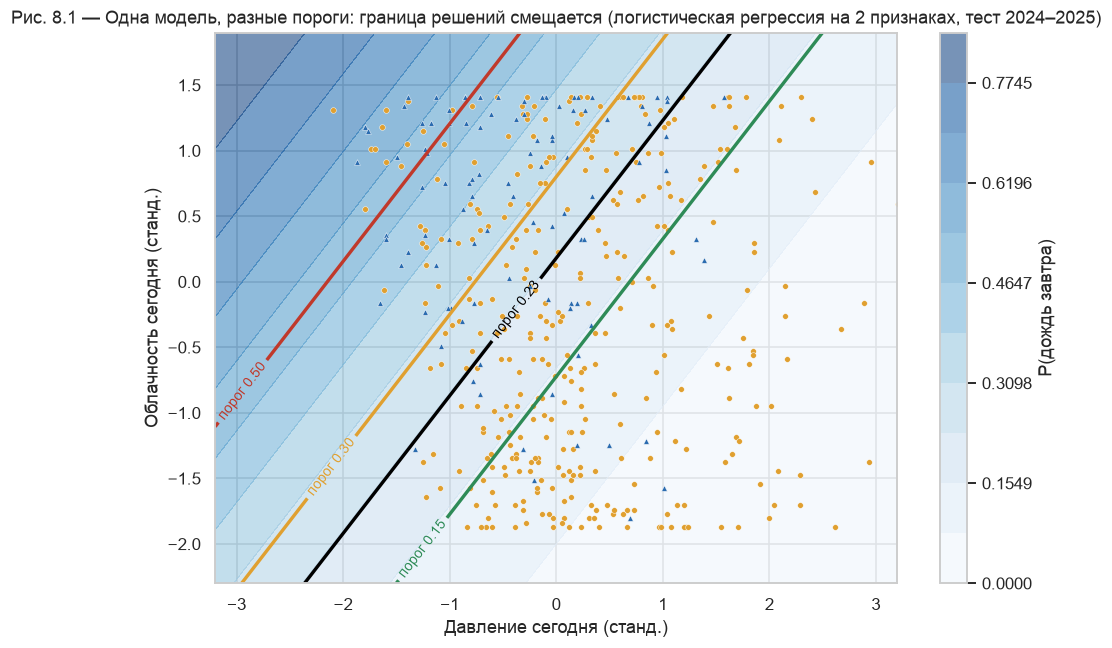

In [3]:
F2 = ["pressure_msl_mean", "cloud_cover_mean"]
sc2 = StandardScaler().fit(train[F2])
A_tr, A_te = sc2.transform(train[F2]), sc2.transform(test[F2])
lr2 = LogisticRegression().fit(A_tr, train[TARGET])
xx, yy = np.meshgrid(np.linspace(-3.2, 3.2, 300), np.linspace(-2.3, 1.9, 300))
P = lr2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(10, 6.5))
cs = ax.contourf(xx, yy, P, levels=np.linspace(0, P.max(), 12), cmap="Blues", alpha=0.55)
plt.colorbar(cs, ax=ax, label="P(дождь завтра)")
for t, col in zip([0.15, THR_F1, 0.3, 0.5], ["#2E8B57", "black", "#E0A030", "#C0392B"]):
    c = ax.contour(xx, yy, P, levels=[t], colors=col, linewidths=2.2)
    ax.clabel(c, fmt={t: f"порог {t:.2f}"}, fontsize=9)
sub = np.random.default_rng(1).choice(len(A_te), 450, replace=False)
for cls, colr, mk in [(0, C_DRY, "o"), (1, C_WET, "^")]:
    m = y_te[sub] == cls
    ax.scatter(A_te[sub][m, 0], A_te[sub][m, 1], color=colr, marker=mk, s=14, edgecolor="white", linewidth=0.3)
ax.set(xlabel="Давление сегодня (станд.)", ylabel="Облачность сегодня (станд.)", xlim=(-3.2, 3.2), ylim=(-2.3, 1.9),
       title="Рис. 8.1 — Одна модель, разные пороги: граница решений смещается (логистическая регрессия на 2 признаках, тест 2024–2025)")
save("fig_8_1_threshold_boundaries")

**Интерпретация.**
- Порог не меняет модель — он меняет только **место, где вероятность превращается в решение**. На рис. 8.1 границы для разных порогов — параллельные линии одной и той же модели.
- **Порог 0.15**: найдено 90 % дождливых дней, но 299 ложных тревог (специфичность 0.48).
- **Порог 0.23** (выбран по F1): баланс — 76 % дождей при 187 ложных тревогах, максимальный F1 = 0.519.
- **Порог 0.5**: самая высокая accuracy (0.82) и всего 19 ложных тревог, но найдено лишь 30 % дождей.
- **Порог 0.8**: модель не объявляет ни одного дождя — её вероятности не превышают ≈ 0.76.
- Ни одна из этих метрик сама по себе не говорит, **какой порог правильный**: это зависит от того, кто пользуется прогнозом и что ему стоят ошибки.

---
## 2. Цена ошибки: кто пользуется прогнозом?

Одна и та же модель служит разным пользователям, и для каждого ошибки стоят по-разному. Рассмотрим три сценария (суммы — **условные оценки** для иллюстрации, в леях за один день):

| Сценарий | FP: ложная тревога | FN: пропущенный дождь | TP: дождь предсказан | TN: сухо предсказано |
|---|---|---|---|---|
| **Фермер** (уборка, сено) | 2 000 — бригада и техника простаивают зря | 12 000 — урожай под дождём | +10 000 — урожай укрыт вовремя | +1 000 — работа по плану |
| **Организатор мероприятия** под открытым небом | 10 000 — аренда шатра и перенос зря | 30 000 — сорванное мероприятие | +20 000 — мероприятие спасено | +5 000 — обычная работа |
| **Дорожная служба** (укладка асфальта) | 5 000 — смена отменена зря | 5 000 — испорченный участок | +3 000 | +3 000 |

Как в материалах, считаем две перспективы: **потери** (только ошибки: FP × c_FP + FN × c_FN) и **чистый результат** (выгода верных решений минус потери).

**Теория.** Если вероятности модели откалиброваны (это так — ноутбук 02), оптимальное правило: объявлять «дождь», когда ожидаемая выгода от тревоги больше, чем от её отсутствия:
$$p\,(g_{TP}+c_{FN}) > (1-p)\,(g_{TN}+c_{FP}) \;\Rightarrow\; t^* = \frac{c_{FP}+g_{TN}}{c_{FP}+g_{TN}+c_{FN}+g_{TP}}$$
(если учитывать только потери — $t^* = c_{FP}/(c_{FP}+c_{FN})$).

In [4]:
SCEN = {
    "Фермер":                   dict(c_fp=2_000,  c_fn=12_000, g_tp=10_000, g_tn=1_000),
    "Организатор мероприятия":  dict(c_fp=10_000, c_fn=30_000, g_tp=20_000, g_tn=5_000),
    "Дорожная служба":          dict(c_fp=5_000,  c_fn=5_000,  g_tp=3_000,  g_tn=3_000),
}
GRID = np.round(np.arange(0.02, 0.96, 0.01), 2)

def economics(y, p, t, c_fp, c_fn, g_tp, g_tn):
    tp, fp, fn, tn = cells4(y, p, t)
    loss = fp * c_fp + fn * c_fn
    gain = tp * g_tp + tn * g_tn
    return loss, gain, gain - loss

def t_theory(c_fp, c_fn, g_tp, g_tn):
    return (c_fp + g_tn) / (c_fp + g_tn + c_fn + g_tp)

rows = []
for name, s in SCEN.items():
    net_va = [economics(y_va, p_va, t, **s)[2] for t in GRID]
    loss_va = [economics(y_va, p_va, t, **s)[0] for t in GRID]
    t_net, t_loss = GRID[int(np.argmax(net_va))], GRID[int(np.argmin(loss_va))]
    for label, t in [("порог 0.5", 0.5), (f"порог по F1 ({THR_F1:.2f})", THR_F1), (f"оптимум по стоимости ({t_net:.2f})", t_net)]:
        loss, gain, net = economics(y_te, p_te, t, **s)
        tp, fp, fn, tn = cells4(y_te, p_te, t)
        rows.append({"Сценарий": name, "Правило": label, "Порог": t, "FP": fp, "FN": fn,
                     "Потери, тыс. лей": loss / 1000, "Выгода, тыс. лей": gain / 1000, "Чистый результат, тыс. лей": net / 1000,
                     "F1": f1_score(y_te, p_te >= t)})
    rows.append({"Сценарий": name, "Правило": f"теория t* = {t_theory(**s):.2f}", "Порог": round(t_theory(**s), 2),
                 **{k: v for k, v in zip(["FP", "FN"], cells4(y_te, p_te, t_theory(**s))[1:3])},
                 "Потери, тыс. лей": economics(y_te, p_te, t_theory(**s), **s)[0] / 1000,
                 "Выгода, тыс. лей": economics(y_te, p_te, t_theory(**s), **s)[1] / 1000,
                 "Чистый результат, тыс. лей": economics(y_te, p_te, t_theory(**s), **s)[2] / 1000,
                 "F1": f1_score(y_te, p_te >= t_theory(**s))})
econ = pd.DataFrame(rows).set_index(["Сценарий", "Правило"])
print("Оптимум выбран на валидации 2023, результат — на тесте 2024–2025 (730 дней)")
econ.round(3)

Оптимум выбран на валидации 2023, результат — на тесте 2024–2025 (730 дней)


Порог   FP   FN  \
Сценарий                Правило                                        
Фермер                  порог 0.5                     0.50   19  113   
                        порог по F1 (0.23)            0.23  187   39   
                        оптимум по стоимости (0.15)   0.15  299   16   
                        теория t* = 0.12              0.12  359   12   
Организатор мероприятия порог 0.5                     0.50   19  113   
                        порог по F1 (0.23)            0.23  187   39   
                        оптимум по стоимости (0.22)   0.22  194   34   
                        теория t* = 0.23              0.23  185   39   
Дорожная служба         порог 0.5                     0.50   19  113   
                        порог по F1 (0.23)            0.23  187   39   
                        оптимум по стоимости (0.49)   0.49   22  112   
                        теория t* = 0.50              0.50   19  113   

                                                     Потери, тыс. лей  \
Сценарий                Правило                                         
Фермер                  порог 0.5                              1394.0   
                        порог по F1 (0.23)                      842.0   
                        оптимум по стоимости (0.15)             790.0   
                        теория t* = 0.12                        862.0   
Организатор мероприятия порог 0.5                              3580.0   
                        порог по F1 (0.23)                     3040.0   
                        оптимум по стоимости (0.22)            2960.0   
                        теория t* = 0.23                       3020.0   
Дорожная служба         порог 0.5                               660.0   
                        порог по F1 (0.23)                     1130.0   
                        оптимум по стоимости (0.49)             670.0   
                        теория t* = 0.50                        660.0   

                                                     Выгода, тыс. лей  \
Сценарий                Правило                                         
Фермер                  порог 0.5                              1030.0   
                        порог по F1 (0.23)                     1602.0   
                        оптимум по стоимости (0.15)            1720.0   
                        теория t* = 0.12                       1700.0   
Организатор мероприятия порог 0.5                              3710.0   
                        порог по F1 (0.23)                     4350.0   
                        оптимум по стоимости (0.22)            4415.0   
                        теория t* = 0.23                       4360.0   
Дорожная служба         порог 0.5                              1794.0   
                        порог по F1 (0.23)                     1512.0   
                        оптимум по стоимости (0.49)            1788.0   
                        теория t* = 0.50                       1794.0   

                                                     Чистый результат, тыс. лей  \
Сценарий                Правило                                                   
Фермер                  порог 0.5                                        -364.0   
                        порог по F1 (0.23)                                760.0   
                        оптимум по стоимости (0.15)                       930.0   
                        теория t* = 0.12                                  838.0   
Организатор мероприятия порог 0.5                                         130.0   
                        порог по F1 (0.23)                               1310.0   
                        оптимум по стоимости (0.22)                      1455.0   
                        теория t* = 0.23                                 1340.0   
Дорожная служба         порог 0.5                                        1134.0   
                        порог по F1 (0.23)                                382.0   
  

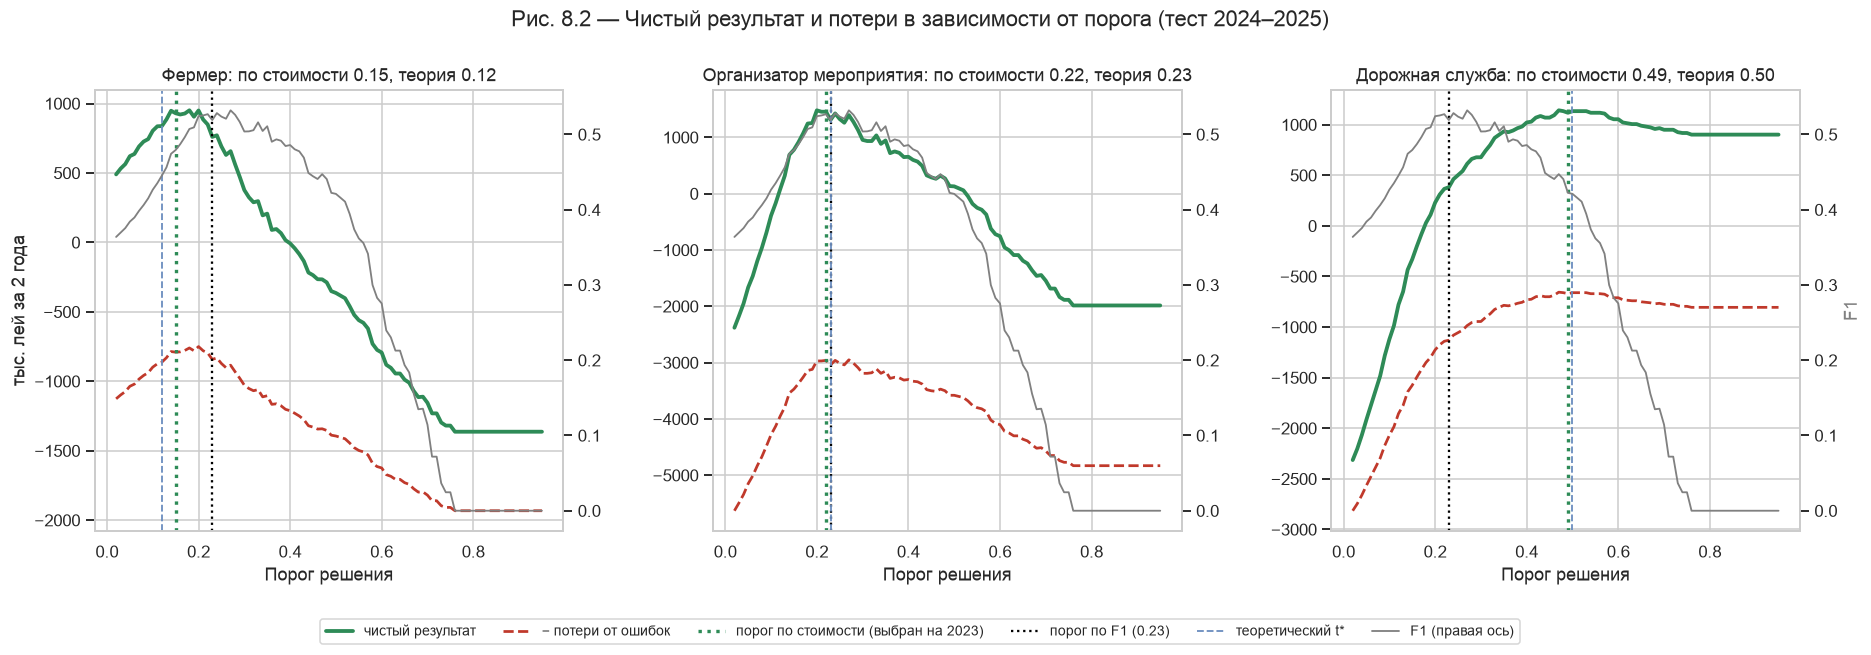

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
f1_curve = [f1_score(y_te, p_te >= t) for t in GRID]
for k, (ax, (name, s)) in enumerate(zip(axes, SCEN.items())):
    net = np.array([economics(y_te, p_te, t, **s)[2] for t in GRID]) / 1000
    loss = np.array([economics(y_te, p_te, t, **s)[0] for t in GRID]) / 1000
    t_val = GRID[int(np.argmax([economics(y_va, p_va, t, **s)[2] for t in GRID]))]   # chosen on 2023, not on the test
    ax.plot(GRID, net, color="#2E8B57", lw=2.5, label="чистый результат")
    ax.plot(GRID, -loss, color="#C0392B", lw=1.8, ls="--", label="− потери от ошибок")
    ax2 = ax.twinx(); ax2.plot(GRID, f1_curve, color="gray", lw=1.2, label="F1 (правая ось)"); ax2.grid(False)
    ax2.set_ylabel("F1" if k == 2 else "", color="gray")
    ax.axvline(t_val, color="#2E8B57", ls=":", lw=2.2, label="порог по стоимости (выбран на 2023)")
    ax.axvline(THR_F1, color="black", ls=":", lw=1.5, label="порог по F1 (0.23)")
    ax.axvline(t_theory(**s), color="#6C8EBF", ls="--", lw=1.2, label="теоретический t*")
    ax.set(xlabel="Порог решения", ylabel="тыс. лей за 2 года" if k == 0 else "",
           title=f"{name}: по стоимости {t_val:.2f}, теория {t_theory(**s):.2f}")
h1, l1 = axes[0].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.1), fontsize=9)
plt.subplots_adjust(wspace=0.32)
fig.suptitle("Рис. 8.2 — Чистый результат и потери в зависимости от порога (тест 2024–2025)", y=1.02)
save("fig_8_2_cost_curves")

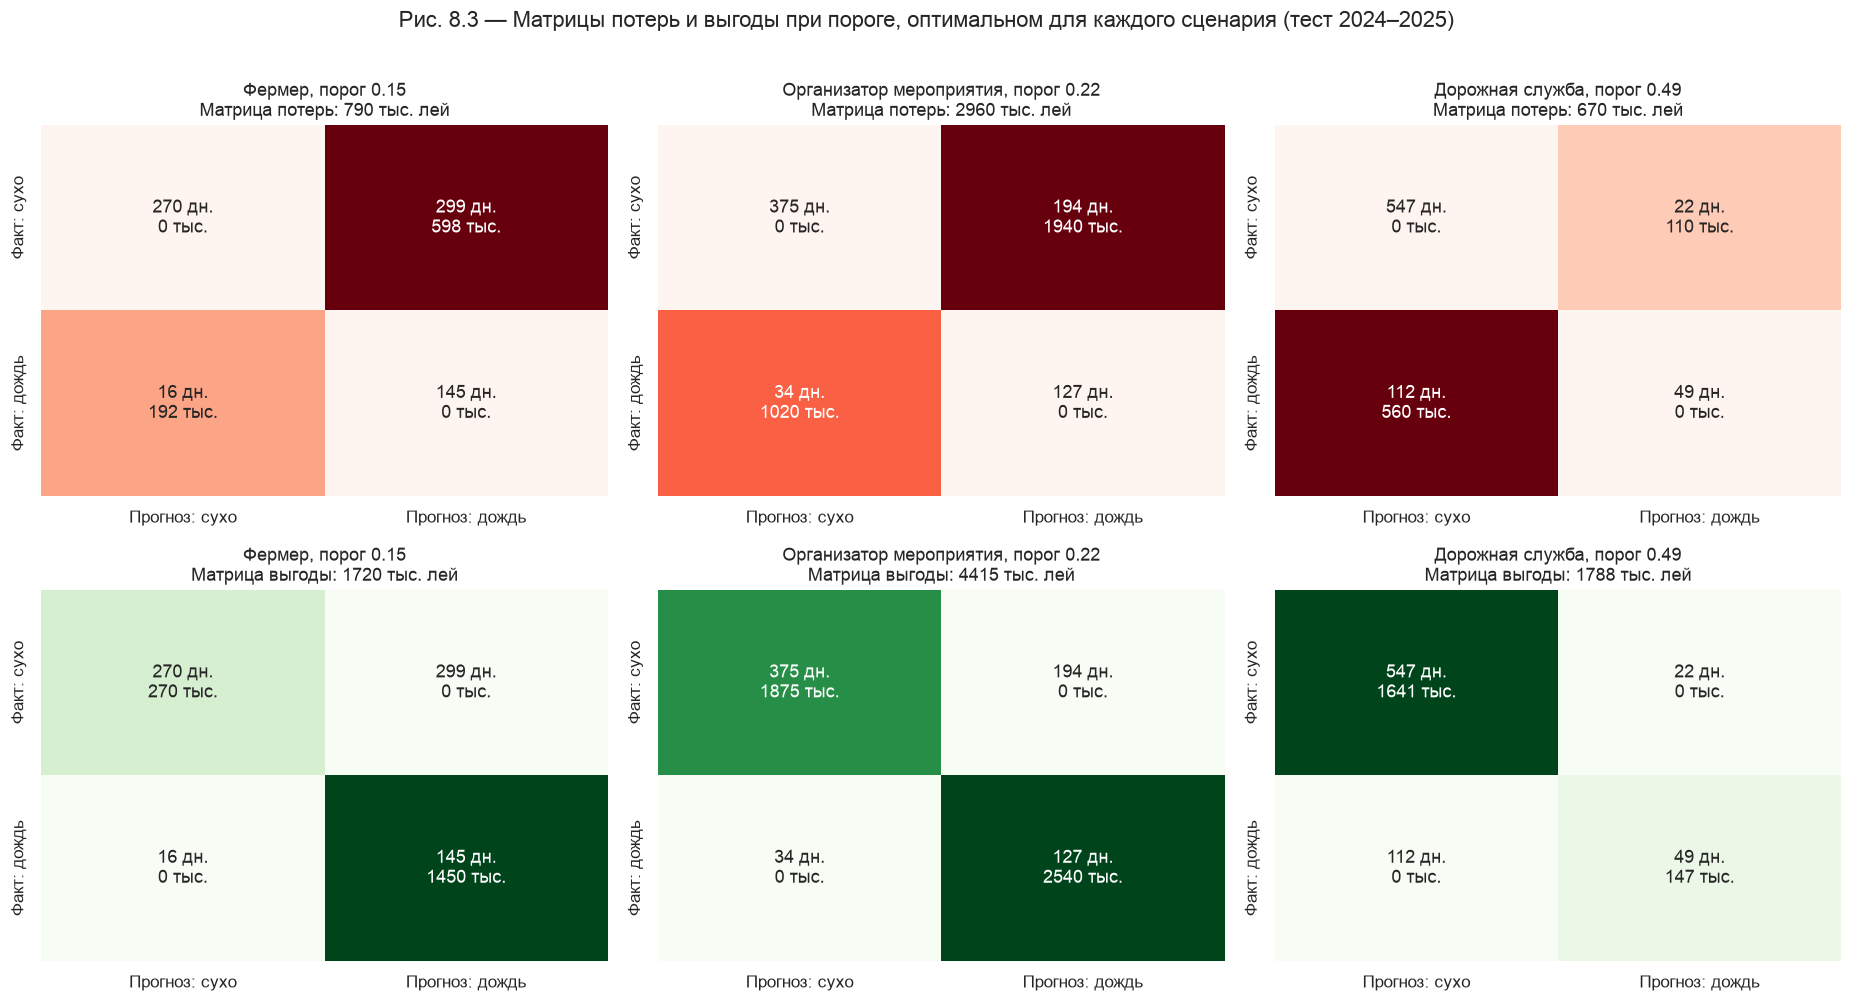

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for j, (name, s) in enumerate(SCEN.items()):
    t_best = GRID[int(np.argmax([economics(y_va, p_va, t, **s)[2] for t in GRID]))]
    tp, fp, fn, tn = cells4(y_te, p_te, t_best)
    cost = np.array([[0, fp * s["c_fp"]], [fn * s["c_fn"], 0]]) / 1000
    prof = np.array([[tn * s["g_tn"], 0], [0, tp * s["g_tp"]]]) / 1000
    for i, (M, cmap, title) in enumerate([(cost, "Reds", "Матрица потерь"), (prof, "Greens", "Матрица выгоды")]):
        cnt = np.array([[tn, fp], [fn, tp]])
        annot = np.array([[f"{cnt[a, b]} дн.\n{M[a, b]:.0f} тыс." for b in range(2)] for a in range(2)])
        sns.heatmap(M, annot=annot, fmt="", cmap=cmap, cbar=False, ax=axes[i, j],
                    xticklabels=["Прогноз: сухо", "Прогноз: дождь"], yticklabels=["Факт: сухо", "Факт: дождь"])
        axes[i, j].set_title(f"{name}, порог {t_best:.2f}\n{title}: {M.sum():.0f} тыс. лей")
fig.suptitle("Рис. 8.3 — Матрицы потерь и выгоды при пороге, оптимальном для каждого сценария (тест 2024–2025)", y=1.01)
plt.tight_layout(); save("fig_8_3_cost_profit_matrices")

**Интерпретация.**
- **Одна модель — три разных лучших порога:** фермер **0.15**, организатор мероприятий **0.22**, дорожная служба **0.49** (выбраны на 2023 году, проверены на 2024–2025).
- **Фермер**: пропущенный дождь в 6 раз дороже ложной тревоги, поэтому выгоднее тревожиться часто. При пороге 0.15 чистый результат **+930 тыс. лей** за 2 года, при пороге по F1 (0.23) — +760 тыс., а при стандартном 0.5 — **убыток −364 тыс.** Его потери в основном из-за ложных тревог (299 × 2 000 = 598 тыс.), а не из-за пропусков (16 × 12 000 = 192 тыс.) — это осознанный выбор.
- **«Максимальный F1 ≠ минимальная стоимость»**: у фермера при лучшем пороге F1 ниже (0.479 против 0.519), а результат на 170 тыс. лей лучше.
- **Дорожная служба**: ошибки обоих видов стоят одинаково, лучший порог ≈ 0.5. Если бы ей дали порог по F1 (0.23), она потеряла бы **≈ 740 тыс. лей** за 2 года (+382 против +1 118 тыс.) из-за 187 зря отменённых смен.
- **Организатор**: соотношение его стоимостей случайно почти совпало с порогом по F1 (0.22 ≈ 0.23).
- **Теория работает:** формула $t^*$ даёт 0.12 / 0.23 / 0.50 — близко к найденным перебором 0.15 / 0.22 / 0.49. Это возможно потому, что вероятности модели откалиброваны (ноутбук 02). На практике порог можно вычислить **из стоимостей, без перебора**, а при изменении цен — сразу пересчитать.
- **Вывод для отчёта:** в системе предупреждений порог должен задаваться **для каждого пользователя** по его стоимостям ошибок, а не один на всех. Код тревоги — это решение, и цена его ошибок разная для разных людей.

---
## 3. Чувствительные точки: дни у самой границы

Чувствительная точка — день, вероятность которого близка к порогу: небольшая ошибка датчика может перевести его в другой класс. Как в приложении преподавателя (зона 0.4–0.6 вокруг порога 0.5), выделяем зону **± 0.05 вокруг нашего порога 0.23** и смотрим:
1. где сосредоточены ошибки модели;
2. как часто шум (σ = 0.35) и смещение (+0.5σ) на входах **меняют решение** в зависимости от удалённости дня от границы (100 повторений шума).

In [7]:
BAND = 0.05
dist = np.abs(p_te - THR_F1)
pred = (p_te >= THR_F1).astype(int)
bins = pd.Series(pd.cut(dist, [0, 0.05, 0.1, 0.2, 0.4, 1.0], include_lowest=True,
                        labels=["< 0.05 (у границы)", "0.05–0.10", "0.10–0.20", "0.20–0.40", "> 0.40 (далеко)"]))
by_bin = lambda v: pd.Series(v).groupby(bins, observed=False).mean() * 100
err_tbl = pd.DataFrame({"Дней": bins.value_counts().sort_index(), "Доля ошибок, %": by_bin(pred != y_te)})

sc = StandardScaler().fit(train[FEATURES]); sd = sc.scale_
rng = np.random.default_rng(SEED)
flips = np.zeros(len(test))
for r in range(100):
    Xn = test[FEATURES].to_numpy() + rng.normal(0, 0.35, (len(test), len(FEATURES))) * sd
    flips += (rf.predict_proba(pd.DataFrame(Xn, columns=FEATURES))[:, 1] >= THR_F1) != pred
flip_rate = flips / 100
pb = rf.predict_proba(pd.DataFrame(test[FEATURES].to_numpy() + 0.5 * sd, columns=FEATURES))[:, 1]
err_tbl["Доля смен решения под шумом σ=0.35, %"] = by_bin(flip_rate)
err_tbl["Доля смен решения при сдвиге +0.5σ, %"] = by_bin((pb >= THR_F1) != pred)
err_tbl.round(1)

,Дней,"Доля ошибок, %","Доля смен решения под шумом σ=0.35, %","Доля смен решения при сдвиге +0.5σ, %"
< 0.05 (у границы),145,46.9,38.3,38.6
0.05–0.10,167,32.3,27.2,40.1
0.10–0.20,299,22.1,17.8,44.8
0.20–0.40,92,33.7,1.7,8.7
> 0.40 (далеко),27,25.9,0.0,0.0


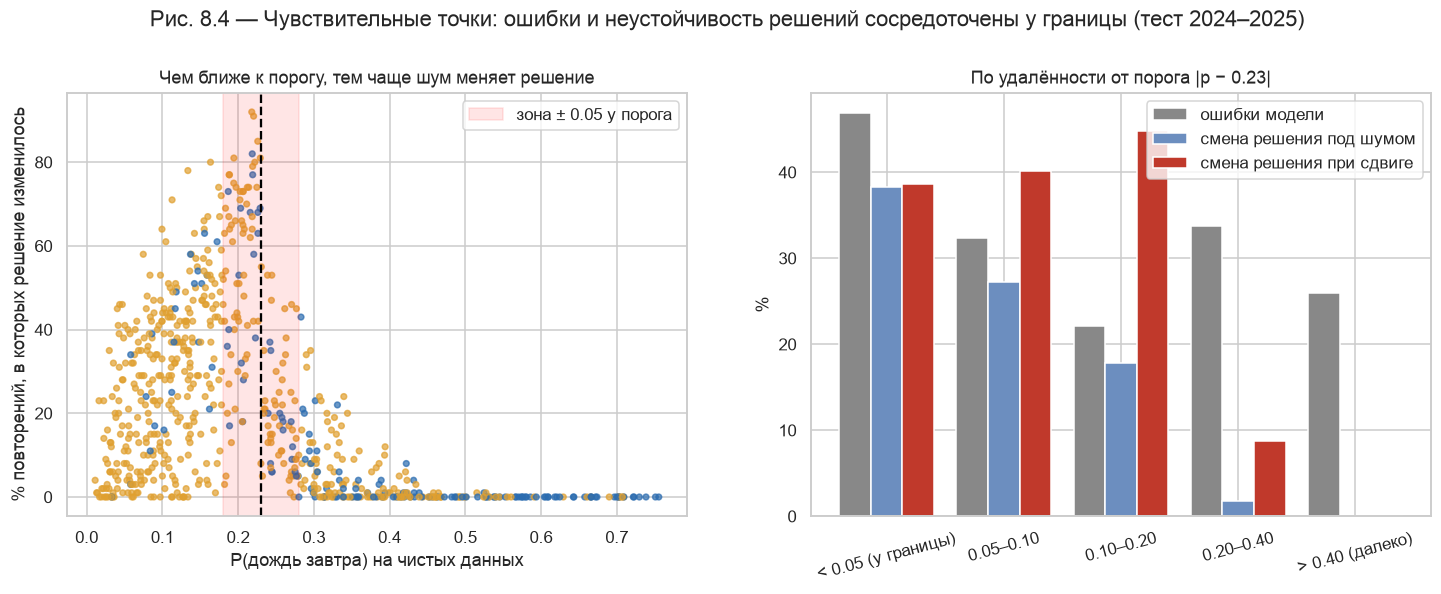

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5))
a1.scatter(p_te, flip_rate * 100, c=np.where(y_te == 1, C_WET, C_DRY), s=14, alpha=0.7)
a1.axvspan(THR_F1 - BAND, THR_F1 + BAND, color="red", alpha=0.1, label=f"зона ± {BAND} у порога")
a1.axvline(THR_F1, color="black", ls="--")
a1.set(xlabel="P(дождь завтра) на чистых данных", ylabel="% повторений, в которых решение изменилось",
       title="Чем ближе к порогу, тем чаще шум меняет решение"); a1.legend()
x = np.arange(len(err_tbl))
a2.bar(x - 0.27, err_tbl["Доля ошибок, %"], 0.27, label="ошибки модели", color="#888888")
a2.bar(x, err_tbl["Доля смен решения под шумом σ=0.35, %"], 0.27, label="смена решения под шумом", color="#6C8EBF")
a2.bar(x + 0.27, err_tbl["Доля смен решения при сдвиге +0.5σ, %"], 0.27, label="смена решения при сдвиге", color="#C0392B")
a2.set_xticks(x, err_tbl.index, rotation=15); a2.set(ylabel="%", title="По удалённости от порога |p − 0.23|"); a2.legend()
fig.suptitle("Рис. 8.4 — Чувствительные точки: ошибки и неустойчивость решений сосредоточены у границы (тест 2024–2025)", y=1.03)
save("fig_8_4_sensitive_points")

In [9]:
near = dist < BAND
bp = test.loc[near, ["date", "pressure_msl_mean", "cloud_cover_mean", "relative_humidity_2m_mean", "pressure_change_1d"]].assign(
    **{"P(дождь)": p_te[near].round(3), "Прогноз": pred[near], "Факт": y_te[near], "Смена решения под шумом, %": (flip_rate[near] * 100).round(0)})
bp.to_csv(ROOT / "data" / "processed" / "boundary_points.csv", index=False)
print(f"Дней в зоне ± {BAND} у порога: {near.sum()} из {len(test)} ({near.mean():.0%}); сохранено в data/processed/boundary_points.csv")
bp.head(10)

Дней в зоне ± 0.05 у порога: 145 из 730 (20%); сохранено в data/processed/boundary_points.csv


,date,pressure_msl_mean,cloud_cover_mean,relative_humidity_2m_mean,pressure_change_1d,P(дождь),Прогноз,Факт,"Смена решения под шумом, %"
3285,2024-01-05,1009.6,37.0,79.0,8.7,0.263,1,0,38.0
3288,2024-01-08,1012.4,100.0,89.0,6.2,0.279,1,1,5.0
3291,2024-01-11,1020.4,66.0,71.0,-10.7,0.245,1,0,53.0
3292,2024-01-12,1018.9,67.0,78.0,-1.5,0.206,0,1,18.0
3293,2024-01-13,1016.9,90.0,80.0,-2.0,0.279,1,0,5.0
3294,2024-01-14,1009.8,66.0,82.0,-7.1,0.270,1,0,5.0
3296,2024-01-16,1005.2,43.0,82.0,0.6,0.248,1,0,23.0
3299,2024-01-19,1003.5,88.0,91.0,0.4,0.230,1,0,8.0
3303,2024-01-23,1027.3,81.0,80.0,-9.1,0.234,1,0,21.0
3304,2024-01-24,1024.8,91.0,85.0,-2.5,0.255,1,1,20.0


**Интерпретация.**
- **20 % тестовых дней (145)** лежат в зоне ± 0.05 у порога 0.23 — это чувствительные точки.
- **Там модель ошибается почти как монетка** — в 46.9 % случаев, тогда как при удалённости 0.10–0.20 только в 22 %. (Высокая доля ошибок в зонах 0.20–0.40 и > 0.40 — это ложные тревоги среди дней с высокой вероятностью дождя: дождь вероятен, но не гарантирован.)
- **Шум (σ = 0.35)** меняет решение в 38 % повторений для дней у границы, в 18 % — при удалённости 0.10–0.20 и практически никогда — при удалённости больше 0.2. Чем ближе к порогу, тем неустойчивее решение.
- **Асимметрия (рис. 8.4, слева):** дни с вероятностью около 0.1 под шумом меняют решение чаще, чем дни с вероятностью около 0.35. Зашумлённые входы «стягивают» прогнозы Random Forest к средней частоте дождя (≈ 0.24), а она почти совпадает с порогом. Поэтому сухие дни легко перескакивают границу вверх.
- **Систематический сдвиг (+0.5σ)** действует иначе: он меняет решение в 38–45 % дней на удалённости вплоть до 0.2 — сдвигается вся «облако» точек, а не только те, что у границы. Это ровно то, что сказано в лекции: при bias чувствительные точки переходят в другой класс **массово**.
- **Принятая мера:** дни в зоне ± 0.05 выгружены в `data/processed/boundary_points.csv` (как в приложении преподавателя). В системе предупреждений для них разумно выдавать не «да/нет», а пометку **«неуверенный прогноз»** и проверять их другими источниками (радар, численный прогноз).

---
## 4. Ответы на вопросы лекции 2

**«Какой порог вы бы выбрали, если каждый контакт стоит 10 €, а каждая продажа приносит 50 €?»** — Действовать стоит, когда ожидаемая выгода больше затрат: $p \cdot 50 > 10$, то есть порог $t = 10 / 50 = 0.2$. Для нашей задачи то же правило: фермеру, у которого защита урожая стоит 2 000 лей, а спасённый урожай — 10 000 + 12 000 лей, выгодно реагировать уже при вероятности ≈ 0.12–0.15.

**«Что вы предпочтёте — пропустить клиентов, которые купили бы, или связаться с теми, кто не купит?»** (у нас: пропустить дождь или поднять ложную тревогу) — Зависит от соотношения цен. Фермер и организатор предпочитают ложные тревоги (пропуск в 3–6 раз дороже), дорожная служба — нейтральна. Поэтому единого «правильного» порога нет.

**«Шум и bias — это плохо или хорошо?»** — В основном плохо: шум делает решения у границы неустойчивыми, bias массово переносит точки в другой класс. Но **контролируемые** версии полезны: небольшой шум в обучении работает как регуляризация (ноутбуки 05–06), а «контролируемый bias» — перевзвешивание классов или сдвиг порога — исправляет дисбаланс.

**«Что можно рекомендовать, учитывая плотность точек у границы?»** — Каждый пятый день попадает в зону неуверенности. Рекомендация: третий вариант решения («неуверенный прогноз»), уточнение такими днями из других источников и особенно тщательный контроль качества датчиков — именно эти дни первыми страдают от шума и сдвигов.

**Итоговый вопрос лекции: «Если модель внедрят завтра, какие решения она будет принимать и сколько будут стоить её ошибки?»** — По тесту 2024–2025 за год:
- **фермеру** (порог 0.15) она будет давать тревогу примерно в 220 днях в году (61 % дней), пропускать около 8 дождей; ошибки обойдутся ≈ 395 тыс. лей в год, а чистый результат ≈ +465 тыс.;
- **организатору** (порог 0.22) — около 160 тревог в год, ≈ 17 пропущенных дождей; ошибки ≈ 1.48 млн лей, чистый результат ≈ +730 тыс.;
- **дорожной службе** (порог 0.49) — всего ≈ 35 тревог в год, но ≈ 56 пропущенных дождей; ошибки ≈ 335 тыс. лей, чистый результат ≈ +560 тыс.

Одна модель, но три разных системы решений. Именно поэтому порог и коды тревоги в приложении настраиваются под пользователя.